![logo](https://climate.copernicus.eu/sites/default/files/2025-03/logoline_c3s.png)

# Plot an ensemble of CMIP6 climate projections

**Last updated:** 2026-10-12

**This notebook can be run on free online platforms, such as Binder, Kaggle and Colab, or they can be accessed from GitHub. The links to run this notebook in these environments are provided here, but please note they are not supported by ECMWF.**

[![binder](https://mybinder.org/badge.svg)](https://mybinder.org/v2/gh/ecmwf-training/c3s-training-submodule-projections/main?labpath=projections-cmip6.ipynb)
[![kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ecmwf-training/c3s-training-submodule-projections/blob/main/projections-cmip6.ipynb)
[![colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecmwf-training/c3s-training-submodule-projections/blob/main/projections-cmip6.ipynb)
[![github](https://img.shields.io/badge/Open%20in-GitHub-black?logo=github)](https://github.com/ecmwf-training/c3s-training-submodule-projections/blob/main/projections-cmip6.ipynb)

## Learning objectives 🎯

This notebook provides a practical introduction on how to access and process [CMIP6 global climate projections](https://cds.climate.copernicus.eu/datasets/projections-cmip6?tab=overview) data available in the Climate Data Store (CDS) of the Copernicus Climate Change Service (C3S). The workflow shows how to compute and visualize the output of an ensemble of models for the annual global average temperature between 1850 to 2100. You will use the `historical` experiment for the temporal period 1850 to 2014 and the three scenarios `SSP1-2.6`, `SSP2-4.5` and `SSP5-8.5` for the period from 2015 to 2100.

Learn [here](https://confluence.ecmwf.int/display/CKB/CMIP6%3A+Global+climate+projections#CMIP6:Globalclimateprojections) more about CMIP6 global climate projections and the CMIP6 experiments in the CDS.

## Prepare your environment

### Install earthkit and cdsapi

We will request data from the Climate Data Store (CDS) with the help of [earthkit](https://earthkit-data.readthedocs.io/en/latest/).

The code below will ensure that the `earthkit` and `cdsapi` packages are installed.  earthkit-data's `cds` source uses the `cdsapi` package under the hood to talk to the CDS, so `cdsapi` needs to be installed too, even though we never import or call it directly.

In [ ]:
%pip install -q earthkit cdsapi

### (Install and) Import libraries

In [17]:
# Library for working with multidimensional arrays
import xarray as xr

# earthkit for retrieving, processing and visualising CDS data
from earthkit import data as ekd
from earthkit import transforms as ekt
from earthkit import plots as ekp
from earthkit.utils.units.convert import convert_units

# Disable warnings for data download via API
import urllib3

urllib3.disable_warnings()

## Explore data

For the sake of simplicity, and to facilitate data download, the tutorial will make use of some of the coarser resolution models that have a smaller data size. It is nevertheless only a choice for this exercise and not a recommendation (since ideally all models, including those with highest resolution, should be used). Many more models are available on the CDS, and when calculating an ensemble of models, it is best practice to use as many as possible for a more reliable output. See [here](https://confluence.ecmwf.int/display/CKB/CMIP6%3A+Global+climate+projections#CMIP6:Globalclimateprojections-Models,gridsandpressurelevels) a full list of models included in the CDS-CMIP6 dataset.

### Search for the data

Having selected the [CMIP6 global climate projections](https://cds.climate.copernicus.eu/datasets/projections-cmip6?tab=overview) dataset, we now need to specify what product type, variables, temporal and geographic coverage we are interested in. These can all be selected in the **"Download data"** tab. In this tab a form appears in which we will select the following parameters to download:

:::{dropdown} Parameters of data to download

- Data: `CMIP6 global climate projections of near-surface air temperature`
- Experiments: `Historical`, `SSP1-2.6`, `SSP2-4.5`, `SSP5-8.5`
- Models: 7 models from Germany, France, UK, Japan and Russia
- Temporal range: `Historical: 1850 - 2014`. `Scenarios: 2015 - 2100`
- Spatial coverage: `Global`
- Format: `NetCDF`, compressed into zip files

:::

At the end of the download form, select **"Show API request"**. This will reveal a block of code, which you can simply copy and paste into a cell of your Jupyter Notebook (see cell below). Having copied the API request into the cell below, running this will retrieve and download the data you requested.

:::{warning}

Please remember to accept the terms and conditions of the dataset, at the bottom of the CDS download form!

:::

### Download the data

Below, we loop through multiple data requests. These include data for different models and scenarios. It is not possible to specify multiple models in one data request as their spatial resolution varies.

We will download monthly aggregated data. These are disseminated as NetCDF files within a zip archive.

If you have not set up your .cdsapirc file, you will be prompted for your CDS credentials when executing the download cell. See [how to api](https://cds.climate.copernicus.eu/how-to-api) for details on how to set up your .cdsapirc file.

In order to loop through the various experiments and models in our data requests, we will specify them as Python 'lists' here:

In [2]:
experiments = ["historical", "ssp126", "ssp245", "ssp585"]

In [3]:
models = [
    "hadgem3_gc31_ll",
    "inm_cm5_0",
    "inm_cm4_8",
    "ipsl_cm6a_lr",
    "miroc_es2l",
    "mpi_esm1_2_lr",
    "ukesm1_0_ll",
]

:::{note}

Note that these are a selection of the lightest models (in terms of data volume), to facilitate download for the sake of this exercise. There are many [more models](https://cds.climate.copernicus.eu/datasets/projections-cmip6?tab=overview) available on the CDS.

:::

Now we can download the data for each model and experiment sequentially. We will do this separately for the historical experiments and for the various future scenarios, given that they refer to two different time periods.

We use earthkit's `from_source()` function with the `cds` source. Each call returns an earthkit data object, which we store in a Python dictionary with the experiment and model as key, so that we can easily access each dataset later on.

In [4]:
# DOWNLOAD DATA FOR HISTORICAL PERIOD

source = "cds"
dataset = "projections-cmip6"

cmip6_data = {}

for model in models:
    request = {
        "download_format": "zip",
        "data_format": "netcdf",
        "temporal_resolution": "monthly",
        "experiment": "historical",
        "level": "single_levels",
        "variable": "near_surface_air_temperature",
        "model": model,
        "year": [str(year) for year in range(1850, 2015)],
        "month": [f"{month:02d}" for month in range(1, 13)],
    }
    cmip6_data[("historical", model)] = ekd.from_source(source, dataset, request)

2026-10-12 11:46:04,366 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 11:46:04,985 INFO Request ID is d4b3e8a6-436a-4402-8b12-c27d0cd313a8
2026-10-12 11:46:05,077 INFO status has been updated to accepted
2026-10-12 11:46:32,652 INFO status has been updated to running
2026-10-12 11:47:01,336 INFO status has been updated to successful


c0cfe6ce5aae5c6af2f6a6464ab82968.zip:   0%|          | 0.00/114M [00:00<?, ?B/s]

  0%|          | 0/4 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmpzipdhlxz/cds-1a2e324b939695cad2fba11c757a407ab55cdc4d04b417fee15b8380e675a460.d/provenance.png magic=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x1d2\x00\x00\x03\x10\x08\x02\x00\x00\x00\x8f\xb3(\x8a\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xddi' content_type=None
2026-10-12 11:47:18,323 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 11:47:19,227 INFO R

79c26638b982e6d38f3c6c75fca65f67.zip:   0%|          | 0.00/96.5M [00:00<?, ?B/s]

...

  0%|          | 0/11 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmpzipdhlxz/cds-8adc99f600db217915c33a6e26d701114491d9fb052f2247c00c863369c17497.d/provenance.png magic=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x1d+\x00\x00\x03\x10\x08\x06\x00\x00\x00\xdbj\x15\xff\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xddy' content_type=None
2026-10-12 15:03:37,373 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 15:03:38,244 INFO R

f5881f305740d9326e0029ddffa1ec35.zip:   0%|          | 0.00/114M [00:00<?, ?B/s]

  0%|          | 0/4 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmpzipdhlxz/cds-f8f078cc5708a2d5a70d7d3889e2b047e01bf5441ee14c5192b037ef3d443c6d.d/provenance.png magic=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x1d\x14\x00\x00\x03\x10\x08\x06\x00\x00\x00B\x92\xccJ\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xddy' content_type=None


In [5]:
# DOWNLOAD DATA FOR FUTURE SCENARIOS

for experiment in experiments[1:]:
    for model in models:
        request = {
            "download_format": "zip",
            "data_format": "netcdf",
            "temporal_resolution": "monthly",
            "experiment": experiment,
            "level": "single_levels",
            "variable": "near_surface_air_temperature",
            "model": model,
            "year": [str(year) for year in range(2015, 2101)],
            "month": [f"{month:02d}" for month in range(1, 13)],
        }
        cmip6_data[(experiment, model)] = ekd.from_source(source, dataset, request)

2026-10-12 15:04:28,025 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 15:04:28,696 INFO Request ID is 5984527d-a8d3-4e98-9df3-f63b0038227b
2026-10-12 15:04:28,797 INFO status has been updated to accepted
2026-10-12 15:05:47,137 INFO status has been updated to successful


774ff064cec5cada57e3a1657381c5ca.zip:   0%|          | 0.00/55.4M [00:00<?, ?B/s]

  0%|          | 0/4 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmpzipdhlxz/cds-b69b1cdf3d0cecf169f0091567578630df35a923a3c50cf21b39d0f9ab45d6ab.d/provenance.png magic=b"\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x12\x84\x00\x00\x03\x10\x08\x02\x00\x00\x00\x9f\xa3'2\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xddg" content_type=None
2026-10-12 15:05:54,562 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 15:05:55,122 INFO R

ae2700f21c0352023314e66a7d53ccc4.zip:   0%|          | 0.00/50.3M [00:00<?, ?B/s]

...

  0%|          | 0/7 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmpzipdhlxz/cds-cf1ddebb3875bdf53fa12a4f3cf70c18d7690e8c87c082cf665b892d00a62c7d.d/provenance.png magic=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x12|\x00\x00\x03\x10\x08\x06\x00\x00\x00\x13Z|\x08\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xdcg' content_type=None
2026-10-12 15:39:56,083 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-12 15:39:56,563 INFO Requ

dafb07492d979a80d99f8f090f6ed14f.zip:   0%|          | 0.00/63.3M [00:00<?, ?B/s]

  0%|          | 0/4 [00:00<?, ?it/s]

Unknown file type, no reader available. path=/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/tmpzipdhlxz/cds-26de5ba964c5cc82e61456469e48889d9aa9cda62e309b7ebba10b6e766f1790.d/provenance.png magic=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x12f\x00\x00\x03\x10\x08\x06\x00\x00\x00#\xd6m)\x00\x00\x00\x06bKGD\x00\xff\x00\xff\x00\xff\xa0\xbd\xa7\x93\x00\x00 \x00IDATx\x9c\xec\xdcg' content_type=None


:::{note}

From the CDS, CMIP6 data are available as `NetCDF` files compressed into `zip` archives. Earthkit takes care of extracting the NetCDF files from the archives for us, so there is no need to unzip the files or to keep track of their file names. Earthkit also caches the downloaded data: if you run the download cells again with the same requests, the data will be taken from the cache instead of being downloaded again.

:::

## Load and prepare CMIP6 data for one model and one experiment

Now that we have downloaded the data, we can prepare it in order to view a time series of the spread of annual global temperature for the model ensemble. These preparation steps include the following:

1. **Spatial aggregation**: to have a single global temperature value for each model/experiment dataset, and for each time step
2. **Temporal aggregation**: from monthly to yearly
3. **Conversion of temperature units** from degrees Kelvin to Celsius
4. **Addition of data dimensions** in preparation for the merging of datasets from different models and experiments

In this section we apply these steps to a single dataset from one model and one experiment. In the next section we merge data from all models/experiments in preparation for the final processing and plotting of the temperature time series.

### Load and inspect data

We begin by loading the data from the `historical` experiment of the first model in our list. The earthkit data object can be converted straight to an [xarray.Dataset](https://xarray.pydata.org/en/stable/generated/xarray.Dataset.html) with the method `to_xarray()`.

The result is a `xarray.Dataset` object with four dimensions: `bnds`, `lat`, `lon`, `time`, of which the dimension `bnds` is not callable.

In [6]:
ds = cmip6_data[("historical", models[0])].to_xarray()
ds

/opt/miniconda3/envs/esmf_env/lib/python3.11/site-packages/earthkit/data/readers/netcdf/reader.py:61: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.open_mfdataset(


<xarray.Dataset> Size: 230MB
Dimensions:    (time: 1980, bnds: 2, lat: 144, lon: 192)
Coordinates:
  * time       (time) object 16kB 1850-01-16 00:00:00 ... 2014-12-16 00:00:00
  * lat        (lat) float64 1kB -89.38 -88.12 -86.88 ... 86.88 88.12 89.38
  * lon        (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
    height     float64 8B 1.5
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object 32kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    lat_bnds   (time, lat, bnds) float64 5MB dask.array<chunksize=(1200, 144, 2), meta=np.ndarray>
    lon_bnds   (time, lon, bnds) float64 6MB dask.array<chunksize=(1200, 192, 2), meta=np.ndarray>
    tas        (time, lat, lon) float32 219MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
Attributes: (12/46)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    creation_date:          2019-06-19T11:21:17Z
    ...                     ...
    title:                  HadGEM3-GC31-LL output prepared for CMIP6
    variable_id:            tas
    variant_label:          r1i1p1f3
    license:                CMIP6 model data produced by the Met Office Hadle...
    cmor_version:           3.4.0
    tracking_id:            hdl:21.14100/b6959414-d5ed-4cd9-a627-59238e52132d

By examining the data above, we can see from the temporal range (1850 to 2014) that it is from the `historical` experiment.

We see that the data dimensions have been given labelled coordinates of time, latitude and longitude. We can find more about the dataset from the `Attributes`, such information includes the model name, description of the variable (`long_name`), units, etc.

Some of this information we will need later, this includes the experiment and model IDs. We will save these into variables:

In [7]:
exp = ds.attrs["experiment_id"]
mod = ds.attrs["source_id"]

An `xarray.Dataset()` may contain arrays of multiple variables. We only have one variable in the dataset, which is near-surface air temperature, `tas`. Below we create an `xarray.DataArray()` object, which takes only one variable, but gives us more flexibility in processing.

In [8]:
da = ds["tas"]

### Spatial aggregation

The next step is to aggregate the temperature values spatially (i.e. average over the latitude and longitude dimensions) and compute the global monthly near-surface temperature.

A very important consideration however is that the gridded data cells do not all correspond to the same areas. The size covered by each data point varies as a function of latitude. We need to take this into account when averaging. One way to do this is to use earthkit's function `spatial.reduce` with `weights="latitude"`, which weights each grid cell by the cosine of its latitude.

The result is a DataArray with one dimension (`time`).

In [9]:
da_agg = ekt.spatial.reduce(da, how="mean", weights="latitude")

### Temporal aggregation

We now aggregate the monthly global near-surface air temperature values to annual global near-surface air temperature values. We can do this with earthkit's function `temporal.mean`, setting the `frequency` to `"year"`. The result is a one-dimensional DataArray with one value per year.

In [10]:
da_yr = ekt.temporal.mean(da_agg, frequency="year")

The time coordinate of the result is still a date. CMIP6 models do not all use the same calendar: some use the standard calendar, others a calendar without leap years or with 360 days per year (e.g. HadGEM3 and UKESM1). Dates from different calendars cannot be combined, so, to be able to combine all models later on, we replace the dates by the year and rename the dimension `time` to `year`:

In [11]:
da_yr = da_yr.assign_coords(time=da_yr.time.dt.year).rename(time="year")

### Conversion from Kelvin to Celsius

The metadata of the original data tells us that the near-surface air temperature data values are in units of Kelvin. We will convert them to degrees Celsius with earthkit's function `convert_units`.

In [12]:
da_yr = convert_units(da_yr, "degC", "K")

### Create additional data dimensions (to later combine data from multiple models & experiments)

Finally, we will create additional dimensions for the experiment and for the model. These we will label with the experiment and model name as taken from the metadata of the original data (see above). These will be useful when we repeat the processes above for all models and experiments, and combine them into one array.

In [13]:
da_yr = da_yr.expand_dims(experiment=[exp], model=[mod])

## Load and prepare CMIP6 data for all models and experiments

To repeat the steps above for all models and all experiments, we will collect all of the commands we have used so far into a function, which we can then apply to the data from all models and experiments.

In [14]:
# Function to compute the annual global mean temperature of one dataset


def global_annual_mean(cmip6_source):
    ds = cmip6_source.to_xarray()
    exp = ds.attrs["experiment_id"]
    mod = ds.attrs["source_id"]
    da = ds["tas"]
    da_agg = ekt.spatial.reduce(da, how="mean", weights="latitude")
    da_yr = ekt.temporal.mean(da_agg, frequency="year")
    da_yr = da_yr.assign_coords(time=da_yr.time.dt.year).rename(time="year")
    da_yr = convert_units(da_yr, "degC", "K")
    da_yr = da_yr.expand_dims(experiment=[exp], model=[mod])
    return da_yr

Now we can apply this function to all the downloaded datasets. The `try` and `except` clauses ensure that all datasets are attempted, even if some fail to be processed. earthkit detects the latitude and longitude coordinates automatically, so data with coordinates labelled as "*latitude*" and "*longitude*" (as for the model *MCM-UA-1-0*) instead of the more commonly applied labels "*lat*" and "*lon*" can also be processed. Any dataset that fails will be recorded in a print statement, and these can be processed separately. See [here](https://confluence.ecmwf.int/display/CKB/CMIP6%3A+Global+climate+projections#CMIP6:Globalclimateprojections-QualitycontroloftheCDS-CMIP6subset) more details on the quality control of the CMIP6 datasets on the CDS.

In [20]:
cmip6_annual = []

for (experiment, model), cmip6_source in cmip6_data.items():
    try:
        cmip6_annual.append(global_annual_mean(cmip6_source))
    except Exception:
        print(f"{experiment} {model} failed")

/opt/miniconda3/envs/esmf_env/lib/python3.11/site-packages/earthkit/data/readers/netcdf/reader.py:61: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.open_mfdataset(
/opt/miniconda3/envs/esmf_env/lib/python3.11/site-packages/earthkit/data/readers/netcdf/reader.py:61: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars expl

In the absence of any print statements, we see that all datasets were successfully processed.

We will now combine the processed data into one dataset for the final steps to create a visualisation of near-surface air temperature from the model ensemble. Since all data arrays have the same coordinates (`experiment`, `model` and `year`), the function `xarray.combine_by_coords` will merge them according to these coordinates. Finally, we select the near-surface air temperature variable, `tas`, as an Xarray DataArray:

In [23]:
data = xr.combine_by_coords(cmip6_annual,combine_attrs="drop_conflicts")["tas"]
data

/opt/miniconda3/envs/esmf_env/lib/python3.11/site-packages/pyarrow/compute.py:230: FutureWarning: Specifying null_placement in RankOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)
/opt/miniconda3/envs/esmf_env/lib/python3.11/site-packages/pyarrow/compute.py:230: FutureWarning: Specifying null_placement in RankOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)
/var/folders/kx/ksg5wbrj1sq95rp2tz_72j6c0000gn/T/ipykernel_3599/1031513993.py:1: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  data = xr.combine_by_coord

<xarray.DataArray 'tas' (experiment: 4, model: 7, year: 251)> Size: 56kB
dask.array<concatenate, shape=(4, 7, 251), dtype=float64, chunksize=(1, 1, 1), chunktype=numpy.ndarray>
Coordinates:
  * experiment  (experiment) object 32B 'historical' 'ssp126' 'ssp245' 'ssp585'
  * model       (model) object 56B 'HadGEM3-GC31-LL' ... 'UKESM1-0-LL'
    height      (model) float64 56B 1.5 2.0 2.0 2.0 2.0 2.0 1.5
  * year        (year) int64 2kB 1850 1851 1852 1853 ... 2097 2098 2099 2100
Attributes:
    standard_name:       air_temperature
    long_name:           Near-Surface Air Temperature
    comment:             near-surface (usually, 2 meter) air temperature
    units:               degC
    cell_measures:       area: areacella
    online_operation:    average
    interval_operation:  900 s
    interval_write:      1 month
    history:             none

## Visualize the CMIP6 annual global average temperature between 1850 and 2100

We will now create a plot of the model ensemble of near-surface air temperature for the historical and future periods, according to the three selected scenarios.

#### Calculate quantiles for model ensemble

Rather than plotting the data from all models, we will instead view the range of values as given by quantiles, including the 10th (near to lower limit), the 50th (mid-range) and the 90th (near to upper limit) quantiles:

In [24]:
data_90 = data.quantile(0.9, dim="model")
data_10 = data.quantile(0.1, dim="model")
data_50 = data.quantile(0.5, dim="model")

> **Note:** A warning message may be shown due to the presence of NaN (Not a Number) data given that the historical and scenario datasets represent only parts (historical and future respectively) of the entire time series. As these two datasets have been merged, NaN values will exist (e.g. there will be no data for the historical experiment for the future period).

### View time-series

Finally we will visualise this data in one time-series plot, using earthkit's `TimeSeries` plotting class. The dimension `year` will be the x-axis and the near-surface air temperature values in degrees Celsius will be the y-axis.

The plotting code below has three main parts:
* **Initiate the plot**: initiate an earthkit time-series plot with `ekp.TimeSeries()`
* **Plot the time-series**: plot the data for each experiment, including the historical experiment and three scenarios, with the `line()` and `fill_between()` methods
* **Set axes limits, labels, title and legend**: Define title and axes labels, and add additional items to the plot, such as legend or gridlines

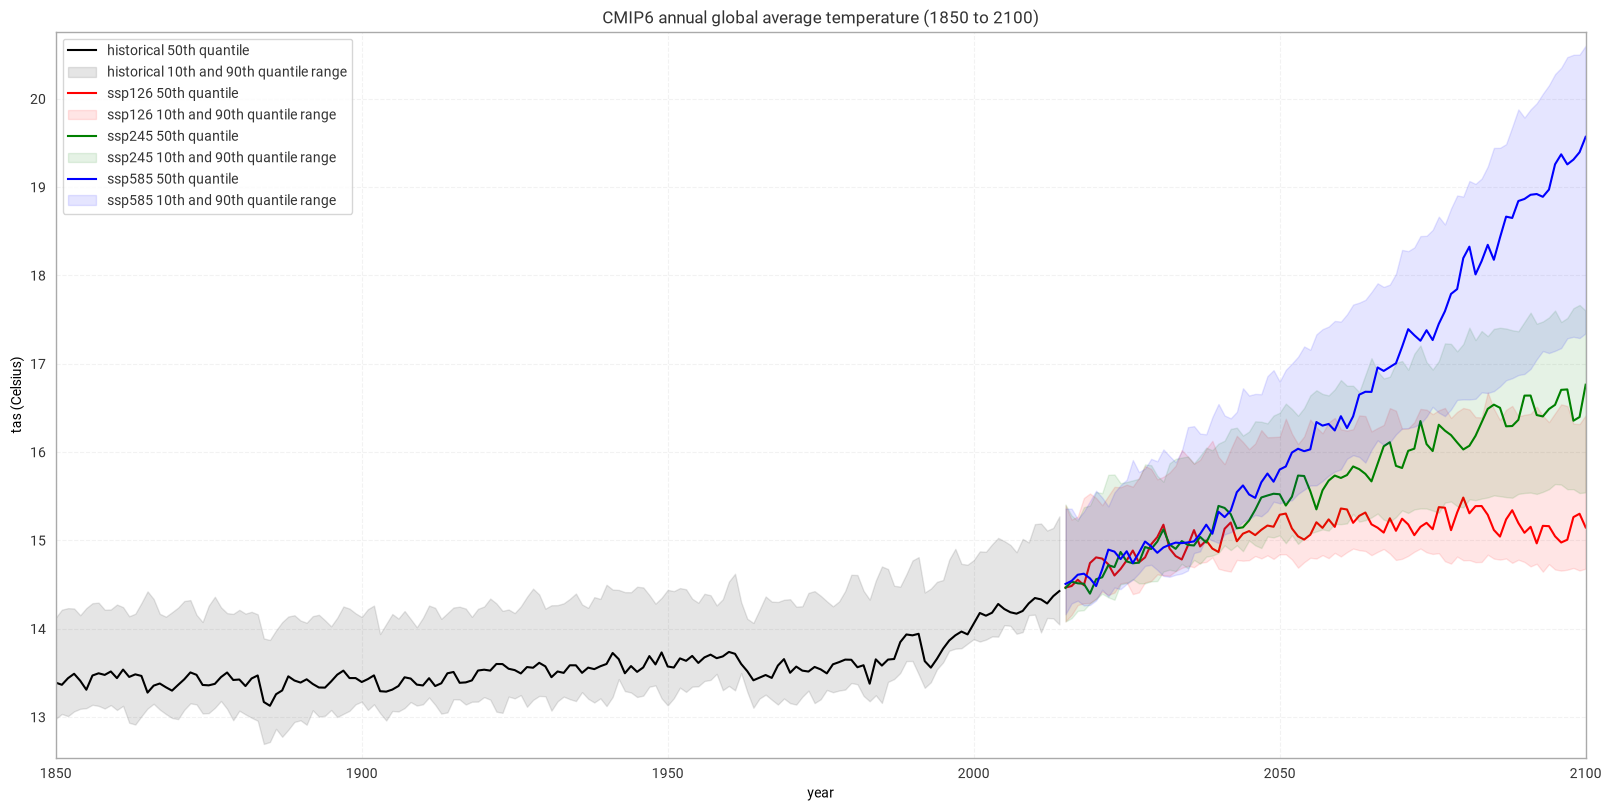

In [25]:
colours = ["black", "red", "green", "blue"]

ts = ekp.TimeSeries(figsize=(16, 8))

for experiment, colour in zip(experiments, colours):
    ts.line(
        data_50.sel(experiment=experiment),
        color=colour,
        label=f"{experiment} 50th quantile",
    )
    ts.fill_between(
        data_10.sel(experiment=experiment),
        data_90.sel(experiment=experiment),
        alpha=0.1,
        color=colour,
        label=f"{experiment} 10th and 90th quantile range",
    )

ts.ax.set_xlim(1850, 2100)
ts.title("CMIP6 annual global average temperature (1850 to 2100)")
ts.ylabel("tas (Celsius)")
ts.xlabel("year")
ts.legend()
ts.ax.grid(linestyle="--")
ts.show()

The visualization of the `CMIP6 annual global average temperature (1850 to 2100)` above shows that the global average temperature was more or less stable in the pre-industrial phase, but steadily increases since the 1990s. It shows further that, depending on the SSP scenario, the course and increase of the global annual temperature differs. While for the best case `SSP1-2.6` scenario, the global annual temperature could stabilize around 15 degC, in the worst case `SSP5-8.5` scenario, the global annual temperature could increase to above 20 degC.

## Take home messages 📌

- An ensemble of models gives a more reliable picture of projected climate than a single model. Quantiles across the models (e.g. the 10th, 50th and 90th) summarise the ensemble and show the spread between the models.

- Global averages of gridded data must take into account that grid cells cover different areas at different latitudes, e.g. by weighting with the cosine of the latitude.

- CMIP6 models use different calendars, so their time coordinates have to be harmonised (here, converted to years) before data from different models can be combined.

- The projected increase in global annual temperature by 2100 depends strongly on the scenario: it is smallest for `SSP1-2.6` and largest for `SSP5-8.5`.